In [1]:
!pip -q install datasets librosa scikit-learn matplotlib


In [2]:
import gc
import time
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16, VGG19, InceptionV3, ResNet50
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_pre
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg19_pre
from tensorflow.keras.applications.inception_v3 import preprocess_input as inception_pre
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_pre

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU: []


In [3]:
ds = load_dataset("SpeechAntiSpoofingBenchmarks/DFADD", split="test")

real_ids = [i for i, row in enumerate(ds) if int(row["label"]) == 0]
spoof_ids = [i for i, row in enumerate(ds) if int(row["label"]) == 1]

rng = np.random.default_rng(SEED)
n = min(len(real_ids), len(spoof_ids), 755)
chosen = np.concatenate([
    rng.choice(real_ids, n, replace=False),
    rng.choice(spoof_ids, n, replace=False)
])
rng.shuffle(chosen)
ds = ds.select(chosen.tolist())

print("Samples:", len(ds))
print("Real (0):", sum(int(row["label"]) == 0 for row in ds))
print("Spoof (1):", sum(int(row["label"]) == 1 for row in ds))


README.md:   0%|          | 0.00/3.70k [00:00<?, ?B/s]

data/test-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  302MB            

data/test-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/test-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  239MB            

data/test-00001-of-00002.parquet: downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/3755 [00:00<?, ? examples/s]

Samples: 1510
Real (0): 755
Spoof (1): 755


In [4]:
IMG_SIZE = 128
X, y = [], []

for i, row in enumerate(ds):
    audio = row["audio"]
    signal = np.asarray(audio["array"], dtype=np.float32)
    sr = audio["sampling_rate"]

    if signal.ndim > 1:
        signal = np.mean(signal, axis=1)

    mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_mels=128)
    mel = librosa.power_to_db(mel, ref=np.max)
    mel = (mel - mel.min()) / (mel.max() - mel.min() + 1e-8)
    mel = tf.image.resize(mel[..., None], (IMG_SIZE, IMG_SIZE)).numpy()
    X.append(np.repeat(mel, 3, axis=-1) * 255.0)
    y.append(int(row["label"]))

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)

print("X:", X.shape, "y:", y.shape)


X: (1510, 128, 128, 3) y: (1510,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)


Train: (1208, 128, 128, 3) Test: (302, 128, 128, 3)


In [6]:
def conv(x, filters, size=3, stride=1):
    return layers.Conv2D(filters, size, strides=stride, padding="same", activation="relu")(x)

def classifier_head(x):
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    return layers.Dense(1, activation="sigmoid")(x)

def inception_block(x, filters):
    a, b, c, d = filters
    p1 = conv(x, a, 1)
    p2 = conv(conv(x, b, 1), b, 3)
    p3 = conv(conv(x, c, 1), c, 5)
    p4 = layers.MaxPooling2D(3, strides=1, padding="same")(x)
    p4 = conv(p4, d, 1)
    return layers.Concatenate()([p1, p2, p3, p4])

def build_model(name):
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))

    if name in ["VGG16", "VGG19", "InceptionV3", "ResNet50"]:
        if name == "VGG16":
            base = VGG16(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            processed = vgg16_pre(inputs)
        elif name == "VGG19":
            base = VGG19(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            processed = vgg19_pre(inputs)
        elif name == "InceptionV3":
            base = InceptionV3(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            processed = inception_pre(inputs)
        else:
            base = ResNet50(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
            processed = resnet_pre(inputs)

        base.trainable = False
        outputs = classifier_head(base(processed, training=False))

    else:
        x = layers.Rescaling(1./255)(inputs)

        if name == "LeNet":
            x = conv(x, 6, 5)
            x = layers.AveragePooling2D(2)(x)
            x = conv(x, 16, 5)
            x = layers.AveragePooling2D(2)(x)
            x = layers.Flatten()(x)
            x = layers.Dense(120, activation="relu")(x)
            x = layers.Dense(84, activation="relu")(x)
            outputs = layers.Dense(1, activation="sigmoid")(x)

        elif name == "AlexNet":
            x = conv(x, 32, 11, 4)
            x = layers.MaxPooling2D(3, 2, padding="same")(x)
            x = conv(x, 64, 5)
            x = layers.MaxPooling2D(3, 2, padding="same")(x)
            x = conv(x, 128)
            x = conv(x, 128)
            x = layers.GlobalAveragePooling2D()(x)
            x = layers.Dense(128, activation="relu")(x)
            x = layers.Dropout(0.4)(x)
            outputs = layers.Dense(1, activation="sigmoid")(x)

        elif name == "GoogLeNet":
            x = conv(x, 32, 7, 2)
            x = layers.MaxPooling2D(3, 2, padding="same")(x)
            x = inception_block(x, [16, 16, 8, 8])
            x = inception_block(x, [24, 24, 12, 12])
            x = layers.MaxPooling2D(2)(x)
            x = inception_block(x, [32, 24, 12, 12])
            outputs = classifier_head(x)

        else:
            raise ValueError("Unknown model: " + name)

    model = Model(inputs, outputs, name=name)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model


In [7]:
MODEL_NAMES = ["LeNet", "AlexNet", "VGG16", "VGG19", "GoogLeNet", "InceptionV3", "ResNet50"]
results = []

for name in MODEL_NAMES:
    print("\\n" + "=" * 55)
    print("Training:", name)
    tf.keras.backend.clear_session()
    gc.collect()

    model = build_model(name)
    early_stop = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    )

    start = time.time()
    model.fit(
        X_train, y_train,
        validation_split=0.2,
        epochs=5,
        batch_size=16,
        callbacks=[early_stop],
        verbose=1
    )
    train_seconds = time.time() - start

    prob = model.predict(X_test, batch_size=16, verbose=0).ravel()
    pred = (prob >= 0.5).astype(np.int32)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Training time (sec)": round(train_seconds, 1)
    })

    model.save(f"VoiceGuard_{name}.keras")
    print("Saved:", f"VoiceGuard_{name}.keras")
    del model
    tf.keras.backend.clear_session()
    gc.collect()

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
results_df


\n=======================================================
Training: LeNet
Epoch 1/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 17s 250ms/step - accuracy: 0.7805 - loss: 0.4436 - val_accuracy: 0.8760 - val_loss: 0.3025
Epoch 2/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 15s 246ms/step - accuracy: 0.8923 - loss: 0.2538 - val_accuracy: 0.9256 - val_loss: 0.2107
Epoch 3/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 15s 248ms/step - accuracy: 0.9358 - loss: 0.1578 - val_accuracy: 0.9380 - val_loss: 0.1555
Epoch 4/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 15s 246ms/step - accuracy: 0.9669 - loss: 0.0934 - val_accuracy: 0.9463 - val_loss: 0.1439
Epoch 5/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 15s 247ms/step - accuracy: 0.9720 - loss: 0.0729 - val_accuracy: 0.9339 - val_loss: 0.1883
Saved: VoiceGuard_LeNet.keras
\n=======================================================
Training: AlexNet
Epoch 1/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 11s 147ms/step - accuracy: 0.5549 - loss: 0.6838 - val_accuracy: 0.7107 - val_loss: 0.6251
Epoch 2/5
61/61 ━━━━━━━━━━━━━━━━━━━━ 10s 142ms/step 

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training time (sec)
6,ResNet50,0.973510,0.986395,0.960265,0.973154,0.998553,384.5
0,LeNet,0.943709,0.940789,0.947020,0.943894,0.985088,83.3
3,VGG19,0.940397,0.946309,0.933775,0.940000,0.986404,1386.5
2,VGG16,0.927152,0.927152,0.927152,0.927152,0.987808,1295.2
5,InceptionV3,0.900662,0.890323,0.913907,0.901961,0.970791,195.0
1,AlexNet,0.834437,0.813665,0.867550,0.839744,0.911451,47.0
4,GoogLeNet,0.708609,0.794393,0.562914,0.658915,0.764484,107.8


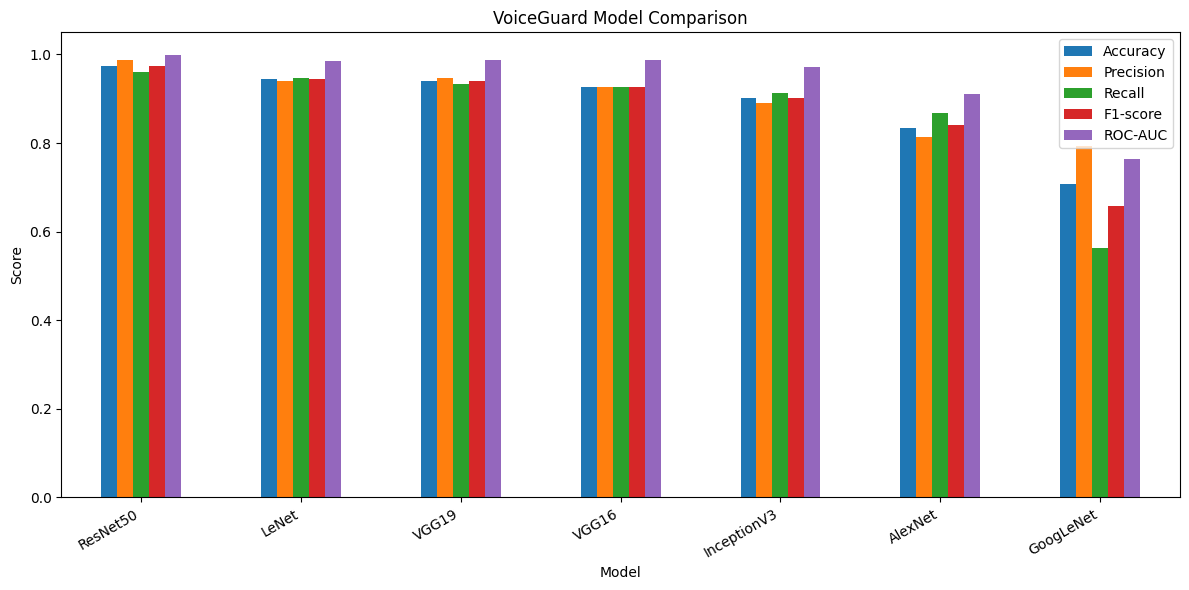

In [8]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
results_df.set_index("Model")[metrics].plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))
plt.title("VoiceGuard Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [9]:
results_df.to_csv("VoiceGuard_model_comparison.csv", index=False)
results_df.to_excel("VoiceGuard_model_comparison.xlsx", index=False)
print("Saved comparison CSV and Excel files.")
display(results_df)


Saved comparison CSV and Excel files.


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Training time (sec)
6,ResNet50,0.973510,0.986395,0.960265,0.973154,0.998553,384.5
0,LeNet,0.943709,0.940789,0.947020,0.943894,0.985088,83.3
3,VGG19,0.940397,0.946309,0.933775,0.940000,0.986404,1386.5
2,VGG16,0.927152,0.927152,0.927152,0.927152,0.987808,1295.2
5,InceptionV3,0.900662,0.890323,0.913907,0.901961,0.970791,195.0
1,AlexNet,0.834437,0.813665,0.867550,0.839744,0.911451,47.0
4,GoogLeNet,0.708609,0.794393,0.562914,0.658915,0.764484,107.8
